In [6]:
#Import
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

Step 1: Uploadd the CSV file

In [14]:
#Upload cSV files
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv("/content/test.csv")

print("Dataset loaded successfully!")
display(df.head())

Saving test.csv to test (3).csv
Dataset loaded successfully!


,Hours,Marks
0,1,35
1,2,40
2,3,45
3,4,50
4,5,55


In [15]:
#Display dataset information
print("Shape: ", df.shape)
print("Columns: ", list(df.columns))
print("\nData types: ")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())

Shape:  (5, 2)
Columns:  ['Hours', 'Marks']

Data types: 
Hours    int64
Marks    int64
dtype: object

Missing values:
Hours    0
Marks    0
dtype: int64


In [16]:
#Change these column names according to your csv files
X_COLUMN = df.columns[0]
Y_COLUMN = df.columns[1]

X = df[X_COLUMN].astype(float).values
Y = df[Y_COLUMN].astype(float).values

print("Independent variable (X):", X_COLUMN)
print("Dependent variable (Y):", Y_COLUMN)

Independent variable (X): Hours
Dependent variable (Y): Marks


In [17]:
#Least Square Regression implementation from scratch

n = len(X)

sum_x = np.sum(X)
sum_y = np.sum(Y)
sum_xy = np.sum(X * Y)
sum_x2 = np.sum(X ** 2)

denominator = n * sum_x2 - (sum_x ** 2)

if denominator == 0:
    raise ValueError("Cannot calculate regression: all X values are identical.")

b1 = (n * sum_xy - sum_x * sum_y) / denominator
b0 = (sum_y - b1 * sum_x) / n

print(f"Intercept (b0): {b0:.4f}")
print(f"Slope (b1): {b1:.4f}")
print(f"Regression equation: Y = {b0:.4f} + {b1:.4f}X")

Intercept (b0): 30.0000
Slope (b1): 5.0000
Regression equation: Y = 30.0000 + 5.0000X


In [18]:
#Make predictions
Y_pred = b0 + b1 * X

results = pd.DataFrame({
    "Actual": Y,
    "Predicted": Y_pred,
    "Residual": Y - Y_pred
})
display(results)

,Actual,Predicted,Residual
0,35.0,35.0,0.0
1,40.0,40.0,0.0
2,45.0,45.0,0.0
3,50.0,50.0,0.0
4,55.0,55.0,0.0


In [19]:
#Evaluate
#Calculate MSE and R-squared without using sklearn

mse = np.mean((Y - Y_pred) ** 2)

ss_res = np.sum((Y - Y_pred) ** 2)
ss_tot = np.sum((Y - np.mean(Y)) ** 2)

r2 = 1 - (ss_res / ss_tot) if ss_tot != 0 else 0

print(f"MSE: {mse:.4f}")
print(f"R-squared: {r2:.4f}")

MSE: 0.0000
R-squared: 1.0000


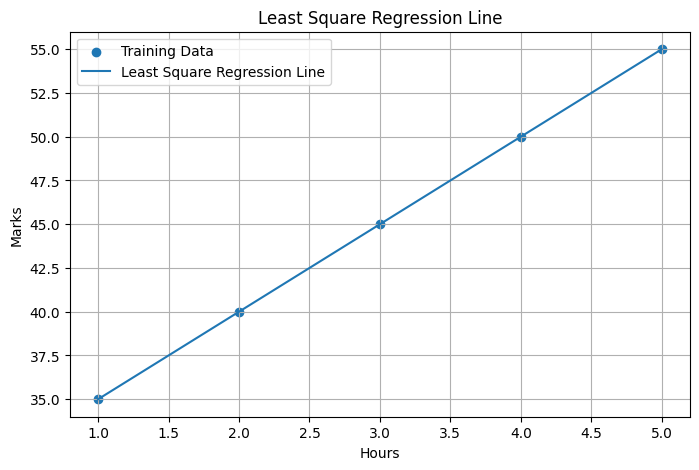

In [20]:
#Plot actual data and Least square regression line

plt.figure(figsize=(8, 5))
plt.scatter(X, Y, label='Training Data')
plt.plot(X, Y_pred, label='Least Square Regression Line')
plt.xlabel(X_COLUMN)
plt.ylabel(Y_COLUMN)
plt.title('Least Square Regression Line')
plt.legend()
plt.grid(True)
plt.show()

In [21]:
#Predict for a new input values

new_x = float(input(f"Enter a new (X_COLUMN) value:"))
new_y = b0 + b1 * new_x

print(f"Predicted (Y_COLUMN) : {new_y:.4f}")

Enter a new (X_COLUMN) value:7
Predicted (Y_COLUMN) : 65.0000
